# A10 - Árboles de decisión

|                |                  |
:----------------|------------------|
| **Nombre**     | Omar Mendoza     |
| **Fecha**      | 16/11/2026       |
| **Expediente** | 757806           |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split

In [2]:
datos = pd.read_excel("DATASET-SALON.xlsx")
datos

,Género,Edad,Estatura
0,M,21,1.80
1,M,21,1.76
2,M,22,1.82
3,M,20,1.67
4,F,22,1.75
5,F,19,1.71
6,M,27,1.79
7,M,20,1.66
8,M,20,1.75


Son 9 alumnos del salon con su genero, edad y estatura, 7 hombres y 2 mujeres

In [3]:
def varianza(x):
    return ((x - x.mean()) ** 2).sum() / (len(x) - 1)

hombres = datos[datos["Género"] == "M"]["Estatura"]
mujeres = datos[datos["Género"] == "F"]["Estatura"]

print("Hombres:", len(hombres), " varianza:", varianza(hombres))
print("Mujeres:", len(mujeres), " varianza:", varianza(mujeres))

Hombres: 7  varianza: 0.003933333333333341
Mujeres: 2  varianza: 0.0008000000000000014


La varianza de la estatura sale 0.0039 en hombres y 0.0008 en mujeres. Es la muestral, por eso se divide entre n - 1. Las mujeres varian menos pero solo son 2

In [4]:
def objetivo(umbral):
    grupo1 = datos[datos["Edad"] < umbral]["Edad"]
    grupo2 = datos[datos["Edad"] > umbral]["Edad"]
    return varianza(grupo1) + varianza(grupo2)

for umbral in [20.5, 21.5]:
    print("Umbral", umbral, " v1 + v2:", objetivo(umbral))

Umbral 20.5  v1 + v2: 6.550000000000001
Umbral 21.5  v1 + v2: 8.9


El mejor corte es 20.5 años con v1 + v2 de 6.55 contra 8.9 de 21.5, separa a los 4 de 20 años o menos de los 5 mayores. No se prueba 19.5 ni 24.5 porque dejan un grupo de un solo alumno y con n - 1 = 0 la varianza no se puede calcular

In [5]:
datos["Menor a 20.5"] = datos["Edad"] < 20.5

datos.groupby(["Menor a 20.5", "Género"])["Estatura"].agg(["count", "mean"])

count      mean
Menor a 20.5 Género                 
False        F           1  1.750000
             M           4  1.792500
True         F           1  1.710000
             M           3  1.693333

Despues del corte por edad se separa por genero y cada hoja predice el promedio de estatura. Los hombres menores a 20.5 promedian 1.693 y los mayores 1.793. Las hojas de mujeres tienen una sola alumna cada una, entonces predicen su propia estatura

In [6]:
advertising = pd.read_csv("Advertising.csv", index_col=0)

X = advertising[["TV", "radio", "newspaper"]]
y = advertising["sales"]

lr = LinearRegression()
lr.fit(X, y)

print("Intercepto:", lr.intercept_)
print("Coeficientes:", lr.coef_)
print("R2:", lr.score(X, y))

Intercepto: 2.938889369459412
Coeficientes: [ 0.04576465  0.18853002 -0.00103749]
R2: 0.8972106381789522


Con todo el dataset la regresion lineal da R2 de 0.897. Radio es el que mas pesa con 0.189 por unidad, despues TV con 0.046, y newspaper casi nada con -0.001

In [7]:
arbol = DecisionTreeRegressor(random_state=42)
arbol.fit(X, y)

print("R2 arbol:", arbol.score(X, y))
print("Profundidad:", arbol.get_depth(), " hojas:", arbol.get_n_leaves())

R2 arbol: 1.0
Profundidad: 13  hojas: 188


El arbol da R2 de 1, ajusta perfecto, pero porque crecio hasta 13 niveles y 188 hojas sin limite. Con 200 datos es casi una hoja por dato, se aprendio los datos de memoria

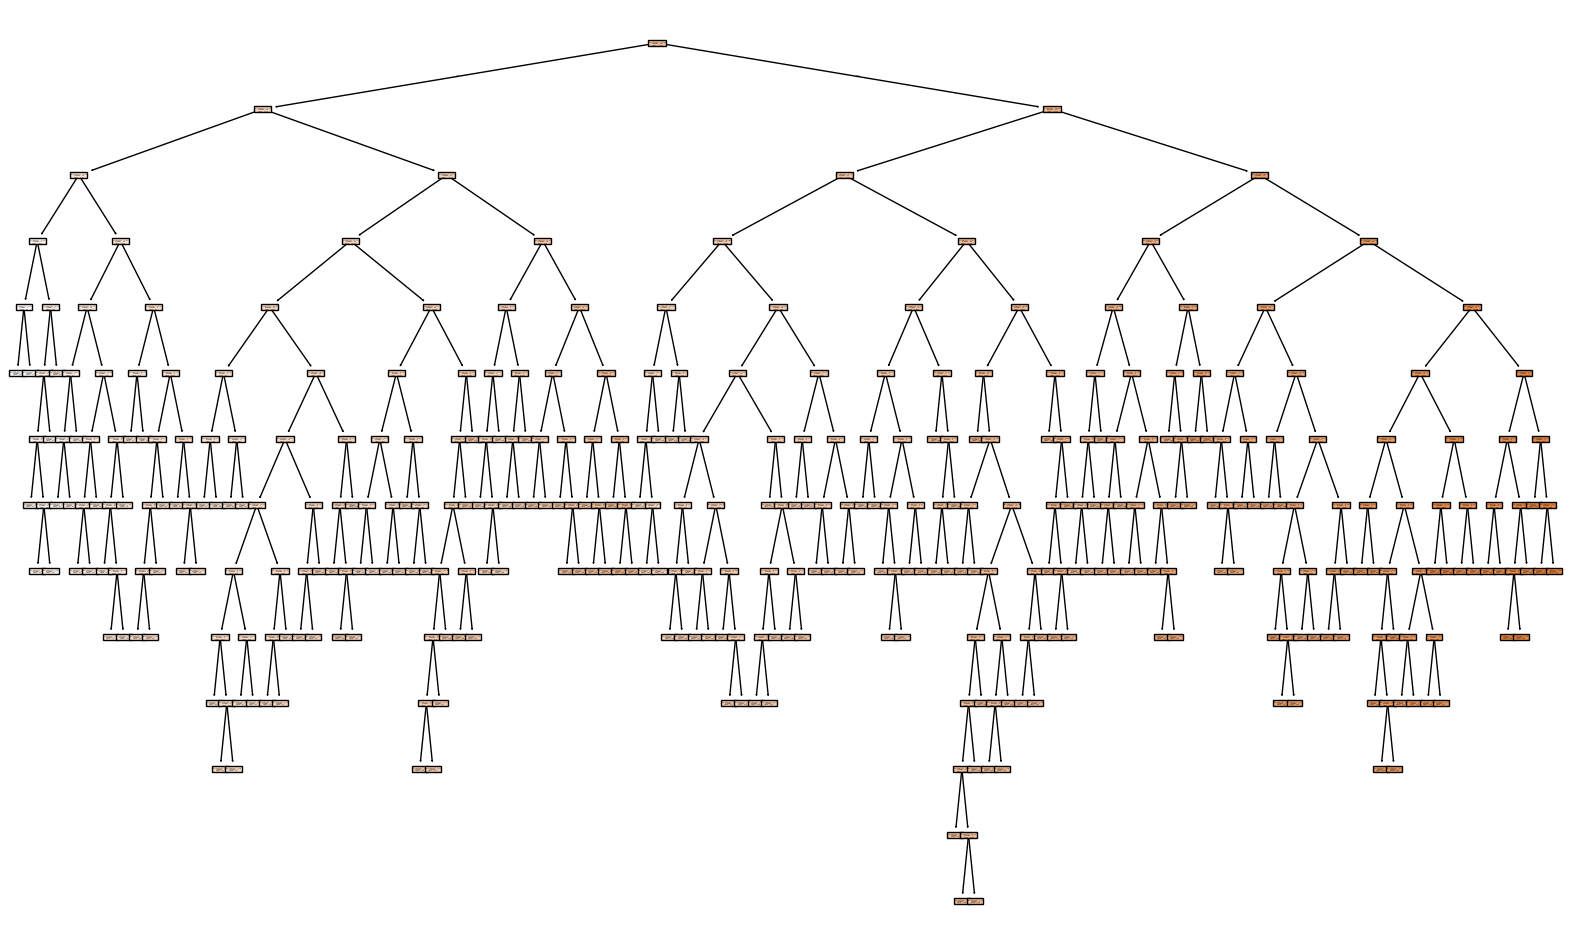

In [8]:
plt.figure(figsize=(20, 12))
plot_tree(arbol, feature_names=X.columns, filled=True)
plt.show()

Por eso la grafica sale enorme y practicamente no se puede leer

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

lr.fit(X_train, y_train)
arbol.fit(X_train, y_train)

pd.DataFrame({
    "modelo": ["Regresion lineal", "Arbol de decision"],
    "R2 train": [lr.score(X_train, y_train), arbol.score(X_train, y_train)],
    "R2 test": [lr.score(X_test, y_test), arbol.score(X_test, y_test)],
}).round(4)

,modelo,R2 train,R2 test
0,Regresion lineal,0.9043,0.8721
1,Arbol de decision,1.0000,0.9345


Partiendo 50 y 50 la regresion lineal baja de 0.904 en train a 0.872 en test. El arbol baja de 1 a 0.935, se sobreajusta pero aun asi le gana en test. Tiene sentido porque la relacion de las ventas con TV y radio no es del todo lineal y el arbol la agarra mejor